In [1]:
pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
individual_household_electric_power_consumption = fetch_ucirepo(id=235) 
  
# data (as pandas dataframes) 
X = individual_household_electric_power_consumption.data.features 
y = individual_household_electric_power_consumption.data.targets 
  
# metadata 
print(individual_household_electric_power_consumption.metadata) 
  
# variable information 
print(individual_household_electric_power_consumption.variables) 


c:\Users\vijay\AppData\Local\Programs\Python\Python314\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (0: Global_active_power, 1: Global_reactive_power, 2: Voltage, 3: Global_intensity, 4: Sub_metering_1, 5: Sub_metering_2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


{'uci_id': 235, 'name': 'Individual Household Electric Power Consumption', 'repository_url': 'https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption', 'data_url': 'https://archive.ics.uci.edu/static/public/235/data.csv', 'abstract': 'Measurements of electric power consumption in one household with a one-minute sampling rate over a period of almost 4 years. Different electrical quantities and some sub-metering values are available.', 'area': 'Physics and Chemistry', 'tasks': ['Regression', 'Clustering'], 'characteristics': ['Multivariate', 'Time-Series'], 'num_instances': 2075259, 'num_features': 9, 'feature_types': ['Real'], 'demographics': [], 'target_col': None, 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2006, 'last_updated': 'Fri Mar 08 2024', 'dataset_doi': '10.24432/C58K54', 'creators': ['Georges Hebrail', 'Alice Berard'], 'intro_paper': None, 'additional_info': {'summary': 'This archiv

In [4]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# Fetch the dataset
dataset = fetch_ucirepo(id=235)

# Extract the features
df = dataset.data.features.copy()

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display the first five rows
print("\nFirst 5 Rows:")
print(df.head())

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check dataset information
print("\nDataset Information:")
df.info()

c:\Users\vijay\AppData\Local\Programs\Python\Python314\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (0: Global_active_power, 1: Global_reactive_power, 2: Voltage, 3: Global_intensity, 4: Sub_metering_1, 5: Sub_metering_2) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Dataset Shape: (2075259, 9)

First 5 Rows:
         Date      Time Global_active_power Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00               4.216                 0.418  234.840   
1  16/12/2006  17:25:00               5.360                 0.436  233.630   
2  16/12/2006  17:26:00               5.374                 0.498  233.290   
3  16/12/2006  17:27:00               5.388                 0.502  233.740   
4  16/12/2006  17:28:00               3.666                 0.528  235.680   

  Global_intensity Sub_metering_1 Sub_metering_2  Sub_metering_3  
0           18.400          0.000          1.000            17.0  
1           23.000          0.000          1.000            16.0  
2           23.000          0.000          2.000            17.0  
3           23.000          0.000          1.000            17.0  
4           15.800          0.000          1.000            17.0  

Column Names:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Volta

In [5]:
# Step 1: Check missing values
print(df.isnull().sum())

Date                         0
Time                         0
Global_active_power          0
Global_reactive_power        0
Voltage                      0
Global_intensity             0
Sub_metering_1               0
Sub_metering_2               0
Sub_metering_3           25979
dtype: int64


In [6]:
# Step 2: Check for '?' values
print((df == '?').sum())

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3               0
dtype: int64


In [7]:
# Step 3: Replace '?' with proper missing values
df.replace('?', pd.NA, inplace=True)

# Check missing values again
print(df.isnull().sum())

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [8]:
# Step 4: Check data types
print(df.dtypes)

Date                         str
Time                         str
Global_active_power       object
Global_reactive_power     object
Voltage                   object
Global_intensity          object
Sub_metering_1            object
Sub_metering_2            object
Sub_metering_3           float64
dtype: object


In [9]:
# Step 5: Convert electricity measurements to numeric values

numeric_columns = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

print(df[numeric_columns].dtypes)

Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object


In [10]:
# Step 6: Check missing values after conversion
print(df.isnull().sum())

Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [11]:
# Step 7: Convert Date to datetime
df['Date'] = pd.to_datetime(
    df['Date'],
    format='%d/%m/%Y',
    errors='coerce'
)

print(df['Date'].dtype)
print(df['Date'].head())

datetime64[us]
0   2006-12-16
1   2006-12-16
2   2006-12-16
3   2006-12-16
4   2006-12-16
Name: Date, dtype: datetime64[us]


In [12]:
# Step 8: Check missing dates
print("Missing dates:", df['Date'].isnull().sum())


Missing dates: 0


In [13]:
# Step 9: Combine Date and Time
df['Datetime'] = pd.to_datetime(
    df['Date'].dt.strftime('%Y-%m-%d') + ' ' + df['Time'],
    errors='coerce'
)

print(df[['Date', 'Time', 'Datetime']].head())
print("Missing datetime values:", df['Datetime'].isnull().sum())

        Date      Time            Datetime
0 2006-12-16  17:24:00 2006-12-16 17:24:00
1 2006-12-16  17:25:00 2006-12-16 17:25:00
2 2006-12-16  17:26:00 2006-12-16 17:26:00
3 2006-12-16  17:27:00 2006-12-16 17:27:00
4 2006-12-16  17:28:00 2006-12-16 17:28:00
Missing datetime values: 0


In [14]:
# Step 10: Check duplicate rows
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [15]:
# Step 11: Check missing values in all columns
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
Datetime                     0
dtype: int64


In [16]:
# Step 12: Count rows with missing electricity readings
missing_rows = df[numeric_columns].isnull().all(axis=1).sum()

print("Rows with all seven readings missing:", missing_rows)
print("Total rows:", len(df))

Rows with all seven readings missing: 25979
Total rows: 2075259


In [17]:
# Step 13: Remove rows with all electricity readings missing
df.dropna(subset=numeric_columns, how='all', inplace=True)

print("Shape after removing missing rows:", df.shape)
print("Remaining missing values:")
print(df[numeric_columns].isnull().sum())

Shape after removing missing rows: (2049280, 10)
Remaining missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


In [18]:
# Step 14: Create time-based features

df['Hour'] = df['Datetime'].dt.hour

df['Day_of_Week'] = df['Datetime'].dt.day_name()

df['Day'] = df['Datetime'].dt.day

df['Month'] = df['Datetime'].dt.month

df['Year'] = df['Datetime'].dt.year

df['Is_Weekend'] = df['Datetime'].dt.dayofweek >= 5

# Display the newly created features
print(df[['Datetime', 'Hour', 'Day_of_Week',
          'Day', 'Month', 'Year', 'Is_Weekend']].head())

print("\nDataset shape:", df.shape)

             Datetime  Hour Day_of_Week  Day  Month  Year  Is_Weekend
0 2006-12-16 17:24:00    17    Saturday   16     12  2006        True
1 2006-12-16 17:25:00    17    Saturday   16     12  2006        True
2 2006-12-16 17:26:00    17    Saturday   16     12  2006        True
3 2006-12-16 17:27:00    17    Saturday   16     12  2006        True
4 2006-12-16 17:28:00    17    Saturday   16     12  2006        True

Dataset shape: (2049280, 16)


In [19]:
# Step 15: Calculate energy consumption in kWh

df['Energy_kWh'] = df['Global_active_power'] / 60

# Display the calculated values
print(df[['Datetime', 'Global_active_power', 'Energy_kWh']].head())

# Check the total calculated energy
print("\nTotal energy consumption (kWh):",
      df['Energy_kWh'].sum())

# Check average energy per minute
print("Average energy per minute (kWh):",
      df['Energy_kWh'].mean())

             Datetime  Global_active_power  Energy_kWh
0 2006-12-16 17:24:00                4.216    0.070267
1 2006-12-16 17:25:00                5.360    0.089333
2 2006-12-16 17:26:00                5.374    0.089567
3 2006-12-16 17:27:00                5.388    0.089800
4 2006-12-16 17:28:00                3.666    0.061100

Total energy consumption (kWh): 37283.74770000001
Average energy per minute (kWh): 0.01819358394167708


In [20]:
# Step 16: Analyze electricity consumption by hour

hourly_consumption = df.groupby('Hour').agg(
    Total_Energy_kWh=('Energy_kWh', 'sum'),
    Average_Energy_kWh=('Energy_kWh', 'mean')
).reset_index()

print(hourly_consumption)

    Hour  Total_Energy_kWh  Average_Energy_kWh
0      0        939.594800            0.010991
1      1        767.999033            0.008989
2      2        684.395667            0.008010
3      3        633.400667            0.007414
4      4        631.128600            0.007397
5      5        644.670100            0.007561
6      6       1124.849900            0.013193
7      7       2135.292933            0.025037
8      8       2076.956700            0.024350
9      9       1893.510900            0.022194
10    10       1791.099467            0.021010
11    11       1770.063900            0.020764
12    12       1716.400333            0.020118
13    13       1627.906233            0.019076
14    14       1541.331533            0.018047
15    15       1409.819100            0.016513
16    16       1349.579533            0.015815
17    17       1500.611700            0.017585
18    18       1886.810367            0.022108
19    19       2471.215800            0.028889
20    20     

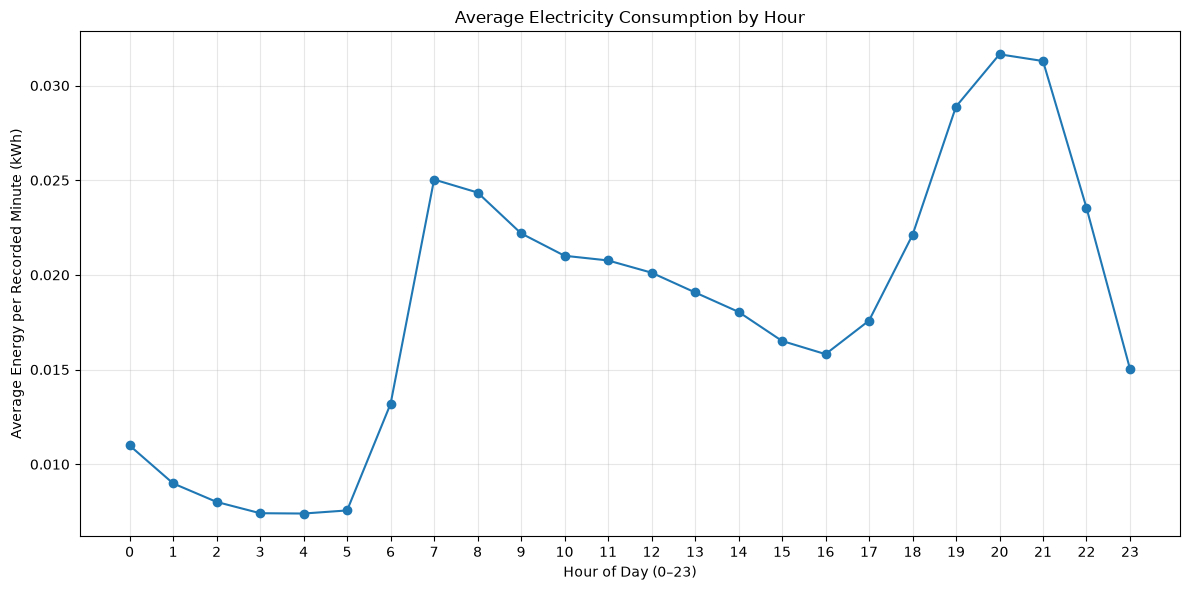

In [21]:
# Step 17: Visualize average consumption by hour

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_consumption['Hour'],
    hourly_consumption['Average_Energy_kWh'],
    marker='o'
)

plt.title('Average Electricity Consumption by Hour')
plt.xlabel('Hour of Day (0–23)')
plt.ylabel('Average Energy per Recorded Minute (kWh)')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
# Step 18: Analyze daily electricity consumption

daily_consumption = df.groupby(
    df['Datetime'].dt.date
).agg(
    Total_Energy_kWh=('Energy_kWh', 'sum'),
    Average_Power_kW=('Global_active_power', 'mean')
).reset_index()

daily_consumption.rename(
    columns={'Datetime': 'Date'},
    inplace=True
)

print(daily_consumption.head(10))

         Date  Total_Energy_kWh  Average_Power_kW
0  2006-12-16         20.152933          3.053475
1  2006-12-17         56.507667          2.354486
2  2006-12-18         36.730433          1.530435
3  2006-12-19         27.769900          1.157079
4  2006-12-20         37.095800          1.545658
5  2006-12-21         28.610400          1.193758
6  2006-12-22         39.022300          1.625929
7  2006-12-23         79.556433          3.314851
8  2006-12-24         42.500200          1.770842
9  2006-12-25         45.718667          1.904944


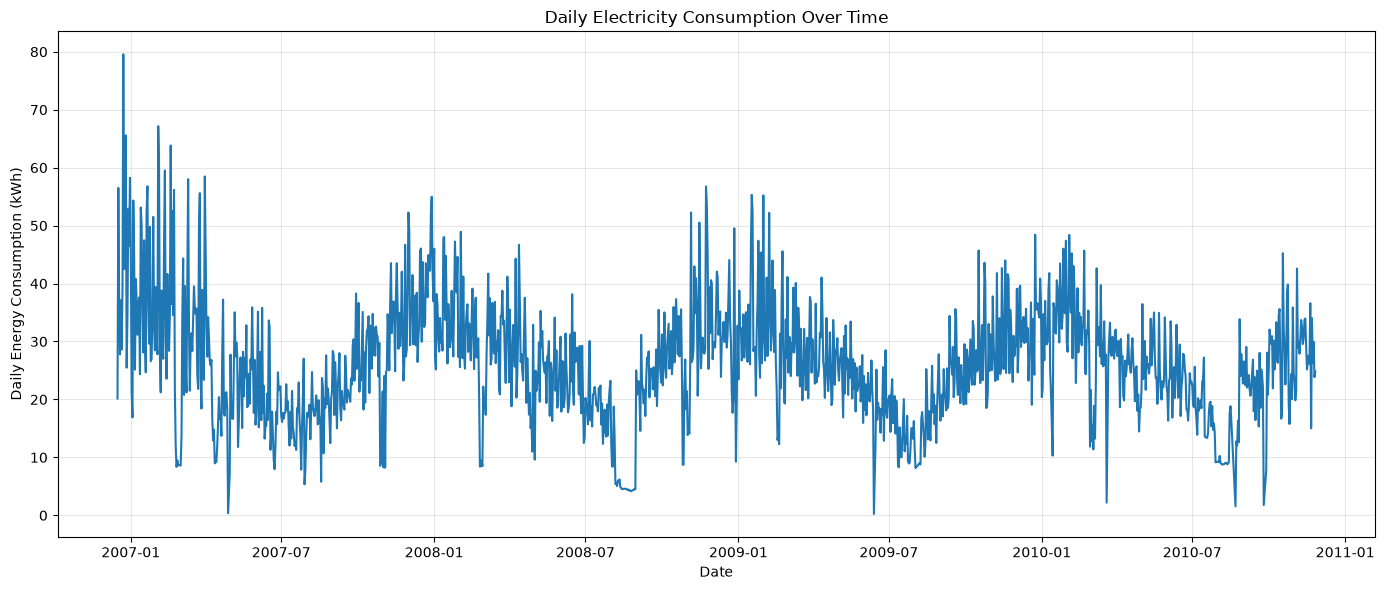

In [23]:
# Step 19: Visualize daily electricity consumption

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    daily_consumption['Date'],
    daily_consumption['Total_Energy_kWh']
)

plt.title('Daily Electricity Consumption Over Time')
plt.xlabel('Date')
plt.ylabel('Daily Energy Consumption (kWh)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
# Step 20: Compare weekday and weekend consumption

weekday_analysis = df.groupby('Is_Weekend').agg(
    Average_Power_kW=('Global_active_power', 'mean'),
    Total_Energy_kWh=('Energy_kWh', 'sum'),
    Reading_Count=('Energy_kWh', 'count')
).reset_index()

weekday_analysis['Day_Type'] = weekday_analysis['Is_Weekend'].map({
    False: 'Weekday',
    True: 'Weekend'
})

print(weekday_analysis[['Day_Type', 'Average_Power_kW',
                        'Total_Energy_kWh', 'Reading_Count']])

  Day_Type  Average_Power_kW  Total_Energy_kWh  Reading_Count
0  Weekday          1.035472      25376.451633        1470428
1  Weekend          1.234232      11907.296067         578852


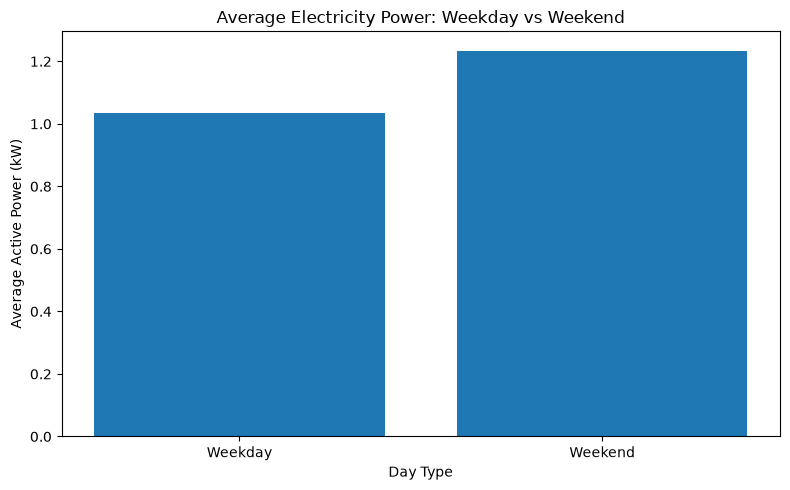

In [25]:
# Step 21: Compare average power on weekdays and weekends

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    weekday_analysis['Day_Type'],
    weekday_analysis['Average_Power_kW']
)

plt.title('Average Electricity Power: Weekday vs Weekend')
plt.xlabel('Day Type')
plt.ylabel('Average Active Power (kW)')

plt.tight_layout()
plt.show()

In [26]:
# Step 22: Analyze monthly electricity consumption

monthly_consumption = df.groupby(
    ['Year', 'Month']
).agg(
    Total_Energy_kWh=('Energy_kWh', 'sum'),
    Average_Power_kW=('Global_active_power', 'mean')
).reset_index()

print(monthly_consumption.head(12))

    Year  Month  Total_Energy_kWh  Average_Power_kW
0   2006     12        696.888033          1.901295
1   2007      1       1150.197700          1.546034
2   2007      2        941.481433          1.401084
3   2007      3        981.036533          1.318627
4   2007      4        586.357767          0.891189
5   2007      5        733.481200          0.985862
6   2007      6        594.713800          0.826814
7   2007      7        495.063833          0.667367
8   2007      8        568.274333          0.764186
9   2007      9        697.876767          0.969318
10  2007     10        821.272833          1.103911
11  2007     11        931.977400          1.294473


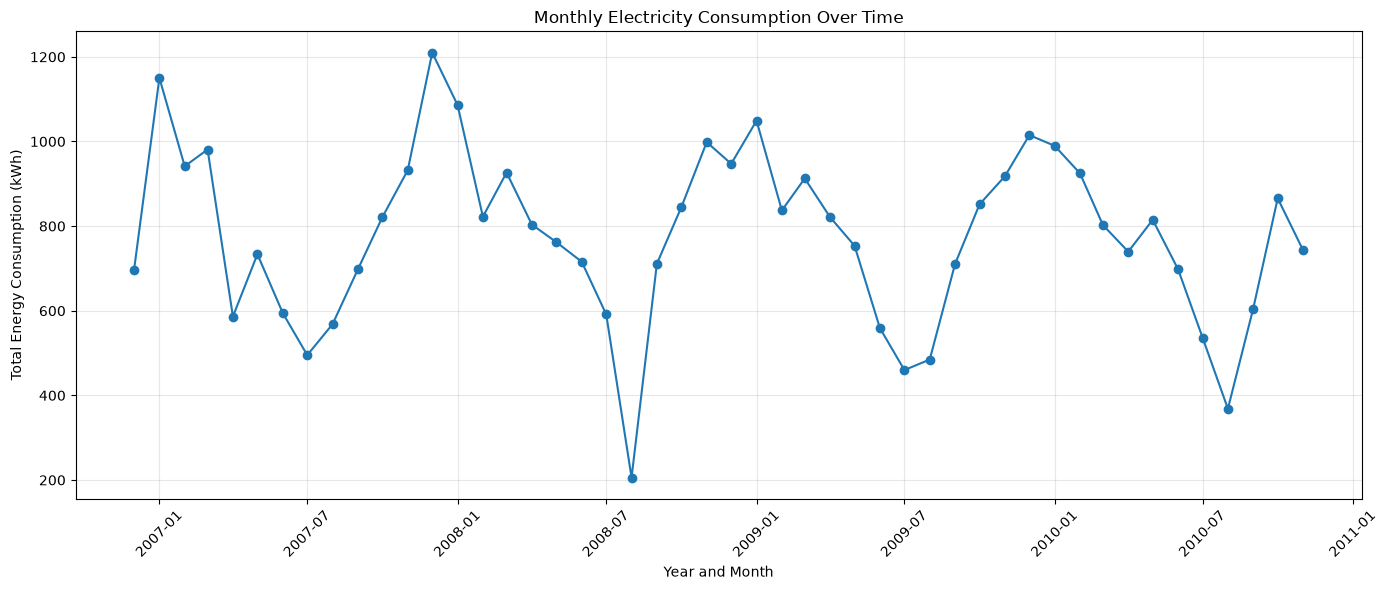

In [27]:
# Step 23: Visualize monthly electricity consumption

import matplotlib.pyplot as plt

# Create a proper date for each month
monthly_consumption['Year_Month'] = pd.to_datetime(
    monthly_consumption[['Year', 'Month']].assign(Day=1)
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_consumption['Year_Month'],
    monthly_consumption['Total_Energy_kWh'],
    marker='o'
)

plt.title('Monthly Electricity Consumption Over Time')
plt.xlabel('Year and Month')
plt.ylabel('Total Energy Consumption (kWh)')
plt.grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
print(df.shape)

(2049280, 17)


In [29]:
df.to_csv("cleaned_electricity_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
